# 7 · Uncertain wear on top of uncertain hours

Update a wear multiplier with EJD-01's conjugate model and see why the mean scale is the wrong point estimate. See [Lesson 7](../docs/lessons/07-uncertain-wear-on-top-of-uncertain-hours.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fracsched.problem import small_problem
from fracsched.utilization_model import default_model

rng = np.random.default_rng(1)
problem = small_problem(0)  # AVR-04's small instance on the flight-hour clock
model = default_model()

posterior mean 0.827, 90 % interval (0.5482356690375603, 1.1531343153444658)
multiplier implied by the mean scale: 0.795


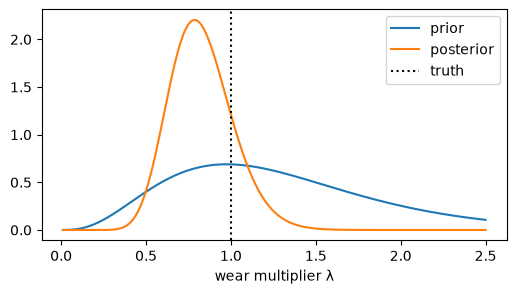

In [2]:
from smallfleet.bayesian_point_estimation import gamma_from_mean_cv

from fracsched.bayesian_risk import plug_in_multiplier, posterior

prior = gamma_from_mean_cv(1.3, 0.5)  # a pessimistic prior from a related fleet
post = posterior(prior, 16, 21.10)  # 16 failures where the reference expects 21.1
print(f"posterior mean {post.mean():.3f}, 90 % interval {post.interval(0.9)}")
print(f"multiplier implied by the mean scale: {plug_in_multiplier(post, 1.8):.3f}")
x = np.linspace(0.01, 2.5, 300)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, [prior.pdf(v) for v in x], label="prior")
ax.plot(x, [post.pdf(v) for v in x], label="posterior")
ax.axvline(1.0, color="k", ls=":", label="truth")
ax.set_xlabel("wear multiplier λ")
ax.legend();